# step1: Create a synthatic classification data using sklearn

In [ ]:
from sklearn.datasets import make_classification

In [ ]:
from numpy import random
x,y = make_classification(
    n_samples = 10,     # number of rows
    n_informative = 2,  # number of useful features
    n_classes = 2,      # Total number of leables present in output class
    n_features = 2,     # Total number of columns
    n_redundant = 0,    # removes repitation of data
    random_state=42
)

In [ ]:
x

array([[ 1.06833894, -0.97007347],
       [-1.14021544, -0.83879234],
       [-2.8953973 ,  1.97686236],
       [-0.72063436, -0.96059253],
       [-1.96287438, -0.99225135],
       [-0.9382051 , -0.54304815],
       [ 1.72725924, -1.18582677],
       [ 1.77736657,  1.51157598],
       [ 1.89969252,  0.83444483],
       [-0.58723065, -1.97171753]])

In [ ]:
y

array([1, 0, 0, 0, 0, 1, 1, 1, 1, 0])

In [ ]:
x.shape

(10, 2)

In [ ]:
y.shape

(10,)

In [ ]:
import torch
# convert data to pytorch tensors
x = torch.tensor(x, dtype = torch.float32)
y = torch.tensor(y, dtype = torch.long)

/tmp/ipykernel_2216/1431818402.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x, dtype = torch.float32)
/tmp/ipykernel_2216/1431818402.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y, dtype = torch.long)


# step2.Import the class and create a custom class

In [ ]:
from torch.utils.data import Dataset, DataLoader

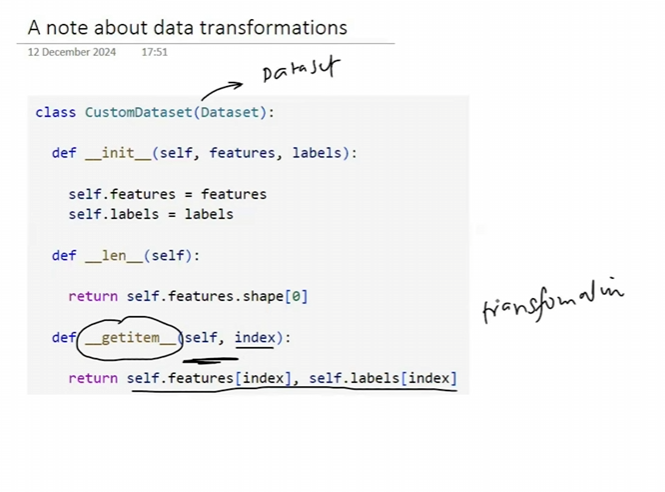

In [ ]:
class customDataset(Dataset):

  def __init__(self,features,leables):
    self.features = features
    self.leables = leables

  def __len__(self):
    return self.features.shape[0]

  def __getitem__(self, index):
    return self.features[index], self.leables[index]

In [ ]:
dataset = customDataset(x,y)

In [ ]:
len(dataset)

10

In [ ]:
dataset[2]

(tensor([-2.8954,  1.9769]), tensor([0]))

# Step3 : create a datalodar class

In [ ]:
dataloder = DataLoader(dataset, batch_size=2, shuffle=True)

In [ ]:
for batch_feature, batch_leable in dataloder:

  print(batch_feature, batch_leable)
  print('-'*50)

tensor([[-2.8954,  1.9769],
        [-1.1402, -0.8388]]) tensor([[0],
        [0]])
--------------------------------------------------
tensor([[-0.5872, -1.9717],
        [ 1.7774,  1.5116]]) tensor([[0],
        [1]])
--------------------------------------------------
tensor([[ 1.0683, -0.9701],
        [-0.9382, -0.5430]]) tensor([[1],
        [1]])
--------------------------------------------------
tensor([[ 1.7273, -1.1858],
        [ 1.8997,  0.8344]]) tensor([[1],
        [1]])
--------------------------------------------------
tensor([[-1.9629, -0.9923],
        [-0.7206, -0.9606]]) tensor([[0],
        [0]])
--------------------------------------------------
